# Quantile Regression of Song Popularity on Audio Features and Artist Popularity Score (APS)

**Research question:** Holding a song's audio features fixed, how is the popularity of the song's *artist* (the Artist Popularity Score, APS) related to song popularity, and do the audio features and the artist score matter differently for weakly, moderately and highly popular songs?

**Why quantile regression?** OLS gives one slope per variable (an effect on the *average* song). Quantile regression estimates a separate slope at each chosen point of the popularity distribution (here the 10th, 25th, 50th, 75th and 90th percentiles), so it can show whether, for example, danceability or artist fame matters more for hit songs than for flops. This follows Raj et al. (ICSCCC 2023), extended with the artist score from the Artist Ranking notebook.

---
## Model specification

**Dependent variable:** $Y_i$ = `song_popularity` of song $i$ (Spotify popularity index, 0-100).

**Independent variables (11):** ten audio features and the artist score. All are z-scored, $\tilde{x} = (x - \bar{x})/s_x$, so every coefficient is *popularity points per 1 standard deviation*. A table of every variable (definition, scale, transformation, summary statistics) is in section 3, and a table of effects in natural units (per minute, per 10 BPM, per 10 APS points, etc.) is in section 8.

**The model** - the conditional $\tau$-th quantile of song popularity:

$$
Q_{\tau}\!\left(Y_i \mid \tilde{\mathbf{x}}_i, \widetilde{APS}_i\right) = \beta_0(\tau) + \sum_{j=1}^{10} \beta_j(\tau)\,\tilde{x}_{ij} + \gamma(\tau)\,\widetilde{APS}_i , \qquad \tau \in \{0.10,\,0.25,\,0.50,\,0.75,\,0.90\}
$$

Written out in full:

$$
\begin{aligned}
Q_\tau(\text{popularity}_i) = \;& \beta_0(\tau) + \beta_1(\tau)\,\text{duration}_i + \beta_2(\tau)\,\text{acousticness}_i + \beta_3(\tau)\,\text{danceability}_i + \beta_4(\tau)\,\text{energy}_i \\
& + \beta_5(\tau)\,\text{instrumentalness}_i + \beta_6(\tau)\,\text{liveness}_i + \beta_7(\tau)\,\text{loudness}_i + \beta_8(\tau)\,\text{speechiness}_i \\
& + \beta_9(\tau)\,\text{tempo}_i + \beta_{10}(\tau)\,\text{valence}_i + \gamma(\tau)\,\text{APS}_i
\end{aligned}
$$

**Estimation:** The coefficients minimize the asymmetric absolute-error loss

$$
\hat{\boldsymbol{\beta}}(\tau) = \arg\min_{\boldsymbol{\beta}} \sum_{i=1}^{n} \rho_\tau\!\big(Y_i - \mathbf{x}_i^{\top}\boldsymbol{\beta}\big), \qquad \rho_\tau(u) = u\,\big(\tau - \mathbf{1}\{u<0\}\big)
$$

so $\tau = 0.5$ is median regression. Over-predictions are penalised with weight $1-\tau$ and under-predictions with weight $\tau$.

**Interpretation:** $\beta_j(\tau)$ is the change in the $\tau$-th quantile of popularity for a 1-SD increase in feature $j$, other variables fixed. $\gamma(\tau)$ is the same for the artist score. It is an association within the sample, not a causal effect.

**Sample:** Only songs whose artist appears in the artist-ranking file (so an APS is available) are used.

## Variables used in Model

| # | Symbol | Column | Role | What it measures | Scale / units | Transformation |
|---|---|---|---|---|---|---|
| - | $Y$ | `song_popularity` | **Dependent** | Spotify's popularity index for the track, based mainly on recent play counts | 0-100 (higher = more popular) | none |
| 1 | $\tilde{x}_1$ | `song_duration_ms` | Independent (audio) | Track length | milliseconds | clipped to 0.5th-99.5th percentile, then z-scored |
| 2 | $\tilde{x}_2$ | `acousticness` | Independent (audio) | Confidence that the track is acoustic (no electric/electronic production) | 0-1 | z-scored |
| 3 | $\tilde{x}_3$ | `danceability` | Independent (audio) | Suitability for dancing from tempo, rhythm stability, beat strength, regularity | 0-1 | z-scored |
| 4 | $\tilde{x}_4$ | `energy` | Independent (audio) | Perceived intensity and activity (fast, loud, noisy tracks score high) | 0-1 | z-scored |
| 5 | $\tilde{x}_5$ | `instrumentalness` | Independent (audio) | Likelihood that the track has no vocals | 0-1 (values near 1 = instrumental) | z-scored |
| 6 | $\tilde{x}_6$ | `liveness` | Independent (audio) | Probability that the track was recorded in front of a live audience | 0-1 | z-scored |
| 7 | $\tilde{x}_7$ | `loudness` | Independent (audio) | Overall average loudness of the track | decibels (dB, negative; closer to 0 = louder) | clipped to 0.5th-99.5th percentile, then z-scored |
| 8 | $\tilde{x}_8$ | `speechiness` | Independent (audio) | Presence of spoken words (rap/talk-heavy tracks score high) | 0-1 | z-scored |
| 9 | $\tilde{x}_9$ | `tempo` | Independent (audio) | Estimated speed of the track | beats per minute (BPM) | z-scored |
| 10 | $\tilde{x}_{10}$ | `audio_valence` | Independent (audio) | Musical positivity (high = happy/cheerful, low = sad/angry) | 0-1 | z-scored |
| 11 | $\widetilde{APS}$ | `APS` | Independent (artist) | Artist Popularity Score: $0.5\,P_{lifetime} + 0.5\,P_{daily}$, where each $P$ is the artist's percentile of log(1 + streams) among the ~3,000 ranked artists | 0-100 (higher = more popular artist) | z-scored within the matched sample |

*Not used:* `key`, `audio_mode`, `time_signature` (excluded in the paper too), plus the artist columns `artist_streams`, `artist_daily`, `artist_as_lead`, `artist_solo`, `artist_as_feature` (APS already summarises lifetime and daily streams).

Summary statistics for these variables in the estimation sample are described later.

## Initialization

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.regression.quantile_regression import hall_sheather
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)

# ---------------- configuration ----------------
TAUS         = [0.10, 0.25, 0.50, 0.75, 0.90]   # quantiles (same as the paper)
WINSORIZE    = True     # clip extreme duration/loudness values to their 0.5th-99.5th percentile
PRIMARY_ONLY = False    # True = keep only songs whose artist score belongs to the song's primary artist
OUT_DIR      = Path("model_c_outputs"); OUT_DIR.mkdir(exist_ok=True)

# features
Y     = "song_popularity"
AUDIO = ["song_duration_ms", "acousticness", "danceability", "energy", "instrumentalness",
         "liveness", "loudness", "speechiness", "tempo", "audio_valence"]
XVARS = AUDIO + ["APS"]                       # raw predictor names
ZVARS = ["z_" + c for c in XVARS]             # standardised predictor names used in the model

## Load the data, attach APS, build the estimation sample

`song_data_with_artists.csv` already holds, for each song, the artist whose stats were looked up (`artist_stats_for`) and that artist's lifetime streams (`artist_streams`). We join it to `artist_popularity_rankings.csv` (which holds the APS) on **artist name + lifetime streams**; both keys are needed because, for example, two different artists in the ranking are both called "Eve".

In [2]:
# helper function to find a file in the current directory or any parent directory
def find_file(filename):
    """Find a file in the current directory or any parent directory."""
    path = Path(filename)
    if path.exists():
        return path
    for parent in Path.cwd().parents:
        candidate = parent / filename
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"File {filename} not found in current or parent directories.")

# load the song data and artist popularity rankings
songs_raw = pd.read_csv(find_file("song_data_with_artists.csv"))
ranks     = pd.read_csv(find_file("artist_popularity_rankings.csv"))
print("songs file:", songs_raw.shape, "| artist rankings file:", ranks.shape)

# every step that removes songs
steps = [("Rows in song file", len(songs_raw))]

songs = songs_raw.drop_duplicates().reset_index(drop=True)          # this Kaggle dataset has many exact duplicates
steps.append(("After dropping exact duplicate rows", len(songs)))

# Rounding avoids failures caused by small floating-point differences.
song_keys = songs.copy()
song_keys["_streams_key"] = pd.to_numeric(
    song_keys["artist_streams"], errors="coerce"
).round(6)

rank_keys = ranks.copy()
rank_keys["_streams_key"] = pd.to_numeric(
    rank_keys["Streams"], errors="coerce"
).round(6)

df = song_keys.merge(
    rank_keys[["Artist", "_streams_key", "APS"]],
    left_on=["artist_stats_for", "_streams_key"],
    right_on=["Artist", "_streams_key"],
    how="left",
    validate="m:1",
).drop(columns=["Artist", "_streams_key"])

df = df[df["tempo"] > 0].copy()                                       # tempo == 0 is a failed measurement
steps.append(("After dropping tempo = 0 (failed measurement)", len(df)))

if WINSORIZE:                                                         # limit leverage of extreme X values
    for c in ["song_duration_ms", "loudness"]:
        lo, hi = df[c].quantile([0.005, 0.995])
        df[c] = df[c].clip(lo, hi)

m = df[df["APS"].notna()].copy()
steps.append(("After keeping songs whose artist has an APS", len(m)))
if PRIMARY_ONLY:
    m = m[m["artist_stats_basis"] == "primary artist"].copy()
    steps.append(("After keeping primary-artist stats only", len(m)))

attr = pd.DataFrame(steps, columns=["Step", "Songs remaining"])
attr["Removed"] = (-attr["Songs remaining"].diff()).fillna(0).astype(int)
display(attr)
print(f"Distinct artists in the estimation sample: {m['artist_stats_for'].nunique():,}")
print("Basis of the artist score:"); display(m["artist_stats_basis"].value_counts().to_frame("songs"))

# z-score every predictor inside the estimation sample
for c in XVARS:
    m["z_" + c] = (m[c] - m[c].mean()) / m[c].std()
MU, SD = m[XVARS].mean(), m[XVARS].std()

songs file: (18835, 25) | artist rankings file: (2994, 10)


,Step,Songs remaining,Removed
0,Rows in song file,18835,0
1,After dropping exact duplicate rows,14926,3909
2,After dropping tempo = 0 (failed measurement),14924,2
3,After keeping songs whose artist has an APS,6181,8743


Distinct artists in the estimation sample: 1,690
Basis of the artist score:


,songs
artist_stats_basis,
primary artist,5740
featured/other artist,441


**Coverage note.** Only songs by artists in the top-~3,000 artist list receive an APS. The estimation sample is therefore a *selected* set of songs by comparatively well-known artists, and results should not be generalised to all songs.

## Summary statistics and relationships among the variables

Estimation sample (original units):


,Role,mean,std,min,median,max,skew,n
song_popularity,Dependent,54.962,20.808,0.000,60.000,100.000,-0.861,6181
song_duration_ms,Audio,220637.589,50192.708,84228.165,214856.000,468497.010,1.105,6181
acousticness,Audio,0.229,0.263,0.000,0.117,0.996,1.216,6181
danceability,Audio,0.632,0.154,0.107,0.642,0.975,-0.307,6181
energy,Audio,0.662,0.200,0.004,0.687,0.997,-0.561,6181
instrumentalness,Audio,0.034,0.135,0.000,0.000,0.966,4.892,6181
liveness,Audio,0.182,0.144,0.012,0.124,0.975,2.130,6181
loudness,Audio,-6.980,3.118,-25.956,-6.333,-1.679,-1.236,6181
speechiness,Audio,0.102,0.102,0.022,0.056,0.891,2.013,6181
tempo,Audio,121.313,28.704,57.000,120.050,216.115,0.456,6181


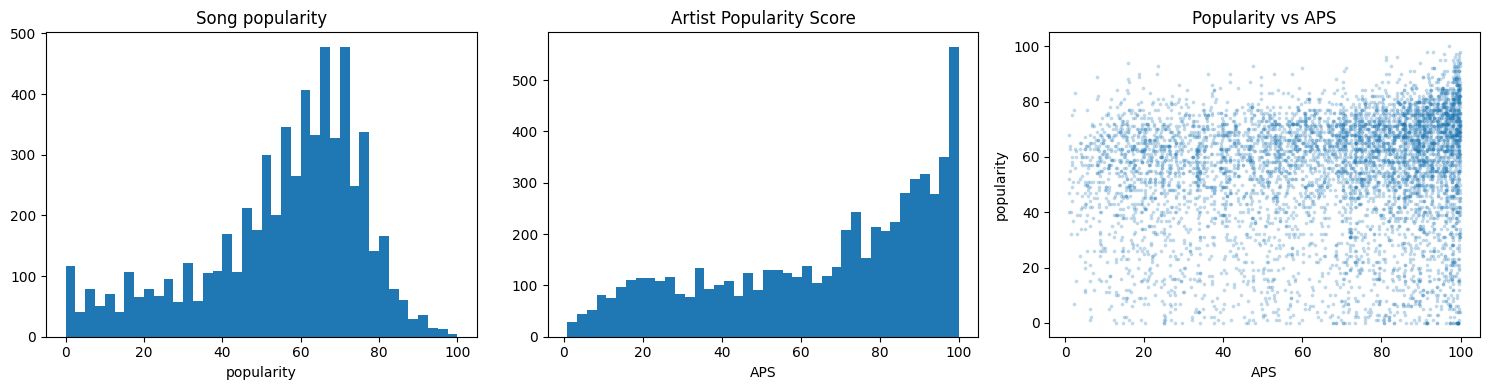

In [3]:
role = {Y: "Dependent", **{c: "Audio" for c in AUDIO}, "APS": "Artist"}
stats = m[[Y] + XVARS].agg(["mean", "std", "min", "median", "max"]).T
stats["skew"] = m[[Y] + XVARS].skew()
stats.insert(0, "Role", [role[i] for i in stats.index])
stats["n"] = len(m)
print("Estimation sample (original units):"); display(stats.round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(m[Y], bins=40); ax[0].set(title="Song popularity", xlabel="popularity")
ax[1].hist(m["APS"], bins=40); ax[1].set(title="Artist Popularity Score", xlabel="APS")
ax[2].scatter(m["APS"], m[Y], s=3, alpha=0.2); ax[2].set(title="Popularity vs APS", xlabel="APS", ylabel="popularity")
plt.tight_layout(); plt.show()

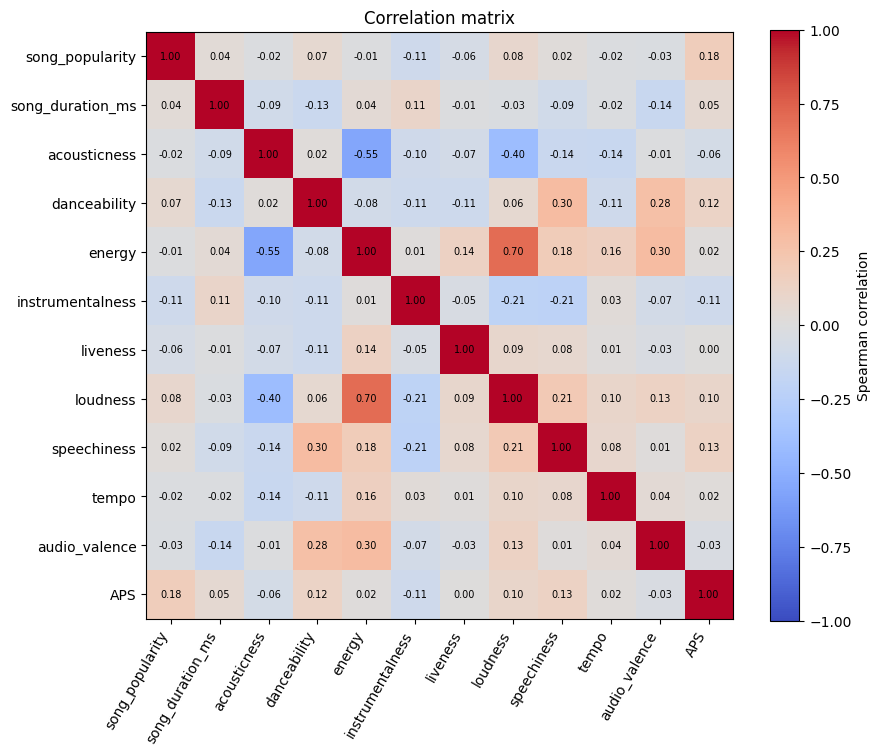

Variance inflation factors (rule of thumb: >5 suggests notable collinearity, >10 serious):


,song_duration_ms,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,audio_valence,APS
VIF,1.06,1.75,1.38,3.45,1.06,1.06,2.42,1.12,1.07,1.41,1.04


In [4]:
# Correlations (Spearman, robust to skew) and multicollinearity (VIF)
corr = m[[Y] + XVARS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Spearman correlation"); ax.set_title("Correlation matrix")
plt.tight_layout(); plt.savefig(OUT_DIR / "correlation_matrix.png", dpi=200); plt.show()

Xv = sm.add_constant(m[ZVARS])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=XVARS, name="VIF")
print("Variance inflation factors (rule of thumb: >5 suggests notable collinearity, >10 serious):")
display(vif.round(2).to_frame().T)

## Why not OLS? Heteroskedasticity check

In [5]:
Xc = sm.add_constant(m[ZVARS])
ols_plain = sm.OLS(m[Y], Xc).fit()
lm, lm_p, _, _ = het_breuschpagan(ols_plain.resid, Xc)
print(f"Breusch-Pagan test on the OLS version of the model: LM = {lm:.1f}, p = {lm_p:.2e}")
print("-> error variance is NOT constant; a single OLS slope can hide differences across the popularity distribution."
      if lm_p < 0.05 else "-> no strong evidence of heteroskedasticity.")

# OLS with artist-clustered standard errors, kept as the 'average effect' benchmark in the plots below
groups = pd.factorize(m["artist_stats_for"])[0]
ols = sm.OLS(m[Y], Xc).fit(cov_type="cluster", cov_kwds={"groups": groups})
print(f"OLS R-squared = {ols_plain.rsquared:.3f}")

Breusch-Pagan test on the OLS version of the model: LM = 39.8, p = 3.93e-05
-> error variance is NOT constant; a single OLS slope can hide differences across the popularity distribution.
OLS R-squared = 0.033


## Model Fit

One quantile regression is fitted for each $\tau$. The first table uses the standard analytic standard errors from `statsmodels`, which treat every song as an independent observation. The next section replaces them with standard errors that allow songs by the same artist to be correlated; those are used for the stars and intervals in all later results. Stars: `***` p<0.01, `**` p<0.05, `*` p<0.10.

Because quantile regression minimizes the asymmetric quantile (check) loss rather than squared error, the Koenker--Machado pseudo-$R^2$ is the primary fit measure: it is $1 - (\text{quantile loss of the model}) / (\text{quantile loss of an intercept-only model})$. Squared-error $R^2$, squared correlation, RMSE and MAE are shown only as diagnostics. A fitted quantile is not meant to track the mean, so these can look poor (even a negative $R^2$) without the model being wrong, and they should not replace the pseudo-$R^2$. The out-of-sample pseudo-$R^2$ at the end of the cell repeats the same calculation on songs whose artists were held out of estimation.


In [6]:
def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

LABEL = {"const": "Intercept", "z_song_duration_ms": "duration", "z_acousticness": "acousticness",
         "z_danceability": "danceability", "z_energy": "energy", "z_instrumentalness": "instrumentalness",
         "z_liveness": "liveness", "z_loudness": "loudness", "z_speechiness": "speechiness",
         "z_tempo": "tempo", "z_audio_valence": "valence", "z_APS": "APS (artist score)"}
NAMES = ["const"] + ZVARS

X = sm.add_constant(m[ZVARS])
fits = {t: sm.QuantReg(m[Y], X).fit(q=t, max_iter=5000) for t in TAUS}
coef = {t: fits[t].params for t in TAUS}          # point estimates, by quantile

# ---------------- analytic coefficient table ----------------
def format_table(coefs, ses):
    out = {}
    for t in TAUS:
        b, se = coefs[t], ses[t]
        p = pd.Series(2 * norm.sf(np.abs(b / se)), index=b.index)
        out[f"tau={t}"] = [f"{b[n]:.3f}{stars(p[n])}" for n in NAMES]
    return pd.DataFrame(out, index=[LABEL[n] for n in NAMES])

print(f"Model analytic standard errors (n = {len(m):,})")
display(format_table({t: fits[t].params for t in TAUS}, {t: fits[t].bse for t in TAUS}))

# ---------------- in-sample fit ----------------
def quantile_loss(y, yhat, tau):
    """Average check (quantile) loss."""
    error = y - yhat
    return np.mean(np.maximum(tau * error, (tau - 1) * error))

y = m[Y].to_numpy()
fit_rows = []
for t in TAUS:
    yhat = fits[t].fittedvalues.to_numpy()
    sse = np.sum((y - yhat) ** 2)
    sst = np.sum((y - y.mean()) ** 2)
    fit_rows.append({
        "pseudo R2 (Koenker-Machado)": fits[t].prsquared,
        "quantile loss": quantile_loss(y, yhat, t),
        "squared-error R2 (diagnostic)": 1 - sse / sst,
        "squared correlation (diagnostic)": np.corrcoef(y, yhat)[0, 1] ** 2,
        "RMSE (diagnostic)": np.sqrt(np.mean((y - yhat) ** 2)),
        "MAE (diagnostic)": np.mean(np.abs(y - yhat)),
        "share of songs at or below fitted quantile": np.mean(y <= yhat),
    })
fit_stats = pd.DataFrame(fit_rows, index=[f"tau={t}" for t in TAUS])
ols_stats = pd.DataFrame({
    "OLS R2": [ols_plain.rsquared],
    "OLS adjusted R2": [ols_plain.rsquared_adj],
    "OLS RMSE": [np.sqrt(np.mean(ols_plain.resid ** 2))],
}, index=["OLS mean regression"])

print("Goodness of fit and in-sample calibration (the last column should be close to tau):")
display(fit_stats.round(4))
print("OLS mean-regression benchmark:")
display(ols_stats.round(4))

# ---------------- out-of-sample pseudo-R2 ----------------
def oos_pseudo_r2(cols, tau, n_splits=5):
    """1 - (model quantile loss / intercept-only quantile loss) on held-out songs.
    Folds are grouped by artist so no artist appears in both training and test sets."""
    yv = m[Y].to_numpy()
    model_loss = baseline_loss = 0.0
    for train, test in GroupKFold(n_splits).split(m, groups=groups):
        X_train = sm.add_constant(m.iloc[train][cols])
        X_test  = sm.add_constant(m.iloc[test][cols], has_constant="add")
        beta = sm.QuantReg(yv[train], X_train).fit(q=tau, max_iter=5000).params.to_numpy()
        baseline = np.full(len(test), np.quantile(yv[train], tau))
        model_loss    += quantile_loss(yv[test], X_test.to_numpy() @ beta, tau) * len(test)
        baseline_loss += quantile_loss(yv[test], baseline, tau) * len(test)
    return 1 - model_loss / baseline_loss

oos = pd.DataFrame({
    f"tau={t}": {"full model": oos_pseudo_r2(ZVARS, t),
                 "APS only":   oos_pseudo_r2(["z_APS"], t),
                 "audio only": oos_pseudo_r2(ZVARS[:-1], t)}
    for t in TAUS
}).T
print("Out-of-sample pseudo-R2 (artist-grouped 5-fold CV):")
display(oos.round(4))
summary = oos

Model analytic standard errors (n = 6,181)


,tau=0.1,tau=0.25,tau=0.5,tau=0.75,tau=0.9
Intercept,22.080***,45.227***,60.401***,69.552***,76.106***
duration,0.462,0.658,0.761***,0.528***,0.189
acousticness,0.082,-0.880,-1.478***,-1.340***,-0.647**
danceability,2.707***,1.159*,0.289,0.845***,1.409***
energy,-2.182,-1.504,-2.367***,-1.712***,-1.452***
instrumentalness,-1.184,-1.602***,-0.952***,-0.917***,-0.775***
liveness,-0.857,-1.349***,-1.209***,-0.613***,-0.349
loudness,0.718,2.156***,2.599***,1.718***,1.834***
speechiness,0.111,-0.708,-0.361,-0.577***,-0.318
tempo,0.595,0.608,-0.408,-0.317,-0.085


Goodness of fit and in-sample calibration (the last column should be close to tau):


,pseudo R2 (Koenker-Machado),quantile loss,squared-error R2 (diagnostic),squared correlation (diagnostic),RMSE (diagnostic),MAE (diagnostic),share of songs at or below fitted quantile
tau=0.1,0.0102,4.4200,-2.4886,0.0140,38.8615,35.1457,0.1010
tau=0.25,0.0136,7.4215,-0.1894,0.0305,22.6913,19.7105,0.2504
tau=0.5,0.0259,7.7661,-0.0394,0.0308,21.2123,15.5322,0.4998
tau=0.75,0.0401,5.2298,-0.4609,0.0313,25.1483,17.7547,0.7494
tau=0.9,0.0553,2.5839,-1.0023,0.0309,29.4412,22.0831,0.8992


OLS mean-regression benchmark:


,OLS R2,OLS adjusted R2,OLS RMSE
OLS mean regression,0.0329,0.0312,20.4611


Out-of-sample pseudo-R2 (artist-grouped 5-fold CV):


,full model,APS only,audio only
tau=0.1,-0.0001,-0.0006,0.0003
tau=0.25,0.0075,0.0048,0.0047
tau=0.5,0.0222,0.0130,0.0095
tau=0.75,0.0372,0.0252,0.0163
tau=0.9,0.0498,0.0343,0.0252


## Standard errors that allow for several songs per artist

The coefficient estimates above do not depend on how standard errors are computed. What does depend on it is how much confidence we can place in them. The 6,000-odd songs come from only about 1,700 artists. Songs by the same artist share the same APS and often a similar sound and audience, so they are not as many independent pieces of evidence as there are rows. The analytic standard errors above assume they are, so they tend to be too small: stars appear too easily and confidence intervals are too narrow. This matters most for APS, which is identical for every song of an artist.

The fix used here is a cluster-robust ("sandwich") covariance estimator for quantile regression (Parente and Santos Silva, 2016), with each artist treated as one cluster. It is a formula evaluated once on the fitted models: no resampling is involved, so the results are identical on every run. It also gives the covariance between the coefficient estimates at *different* quantiles, which is needed to test whether a slope differs between, say, the 10th and the 90th percentile (next sections).

Estimates at the extreme quantiles ($\tau$ = 0.10 and 0.90) are the least precise under any method, so treat borderline p-values there with extra caution.


In [7]:
def cluster_robust_cov(fits, X, y, groups, taus):
    """Artist-clustered (sandwich) covariance of the quantile-regression coefficients.

    Returns {(tau_a, tau_b): covariance matrix of (beta_hat(tau_a), beta_hat(tau_b))}.
    Blocks with tau_a == tau_b are the usual coefficient variances. The off-diagonal blocks
    are needed to test whether one slope differs between two quantiles.
    """
    Xv = X.to_numpy(); n, k = Xv.shape
    g = pd.factorize(groups)[0]; G = g.max() + 1                     # G = number of artists (clusters)
    H_inv, scores = {}, {}
    for t in taus:
        e = y - Xv @ fits[t].params.to_numpy()                       # residuals at this quantile
        iqr = np.subtract(*np.percentile(e, [75, 25]))
        h = hall_sheather(n, t) * min(e.std(), iqr / 1.34)           # kernel bandwidth (same rule as statsmodels)
        dens = norm.pdf(e / h) / h                                   # local density of the residuals at zero
        H_inv[t] = np.linalg.inv((Xv * dens[:, None]).T @ Xv / n)
        s = np.zeros((G, k))                                         # sum of (tau - 1{e<0}) * x within each artist
        np.add.at(s, g, Xv * (t - (e < 0))[:, None])
        scores[t] = s
    return {(a, b): H_inv[a] @ (scores[a].T @ scores[b] / n) @ H_inv[b] / n * G / (G - 1)
            for a in taus for b in taus}

cl_cov = cluster_robust_cov(fits, X, y, groups, TAUS)
cl_se  = {t: pd.Series(np.sqrt(np.diag(cl_cov[(t, t)])), index=NAMES) for t in TAUS}

print(f"Artist-clustered standard errors (n = {len(m):,} songs, {groups.max() + 1:,} artists); stars use these")
tab_C = format_table(coef, cl_se)
display(tab_C)

ratio = pd.DataFrame({f"tau={t}": (cl_se[t] / fits[t].bse).to_numpy() for t in TAUS}, index=[LABEL[n] for n in NAMES])
print("Clustered SE / analytic SE  (above 1 = the analytic SE understated the uncertainty):")
display(ratio.round(2))

coef_long = pd.DataFrame([
    {"tau": tau, "variable": LABEL[name], "coefficient": coef[tau][name],
     "analytic_se": fits[tau].bse[name], "clustered_se": cl_se[tau][name]}
    for tau in TAUS for name in NAMES
])


Artist-clustered standard errors (n = 6,181 songs, 1,690 artists); stars use these


,tau=0.1,tau=0.25,tau=0.5,tau=0.75,tau=0.9
Intercept,22.080***,45.227***,60.401***,69.552***,76.106***
duration,0.462,0.658,0.761**,0.528**,0.189
acousticness,0.082,-0.880,-1.478***,-1.340***,-0.647**
danceability,2.707***,1.159*,0.289,0.845***,1.409***
energy,-2.182,-1.504*,-2.367***,-1.712***,-1.452***
instrumentalness,-1.184***,-1.602***,-0.952**,-0.917***,-0.775***
liveness,-0.857,-1.349***,-1.209***,-0.613***,-0.349*
loudness,0.718,2.156**,2.599***,1.718***,1.834***
speechiness,0.111,-0.708,-0.361,-0.577**,-0.318
tempo,0.595,0.608,-0.408,-0.317,-0.085


Clustered SE / analytic SE  (above 1 = the analytic SE understated the uncertainty):


,tau=0.1,tau=0.25,tau=0.5,tau=0.75,tau=0.9
Intercept,1.39,1.16,1.23,1.14,1.17
duration,0.92,1.50,1.09,1.02,1.14
acousticness,1.48,1.00,1.04,1.05,1.19
danceability,0.92,1.03,1.02,1.04,1.01
energy,1.48,0.89,0.94,0.94,1.00
instrumentalness,0.41,1.01,1.40,1.01,0.75
liveness,0.82,0.82,0.88,1.05,0.87
loudness,1.09,1.14,1.04,0.96,1.09
speechiness,1.96,0.91,0.86,1.25,1.09
tempo,1.45,0.85,0.99,0.97,1.18


## How coefficients change across quantiles (compared with the OLS average effect)

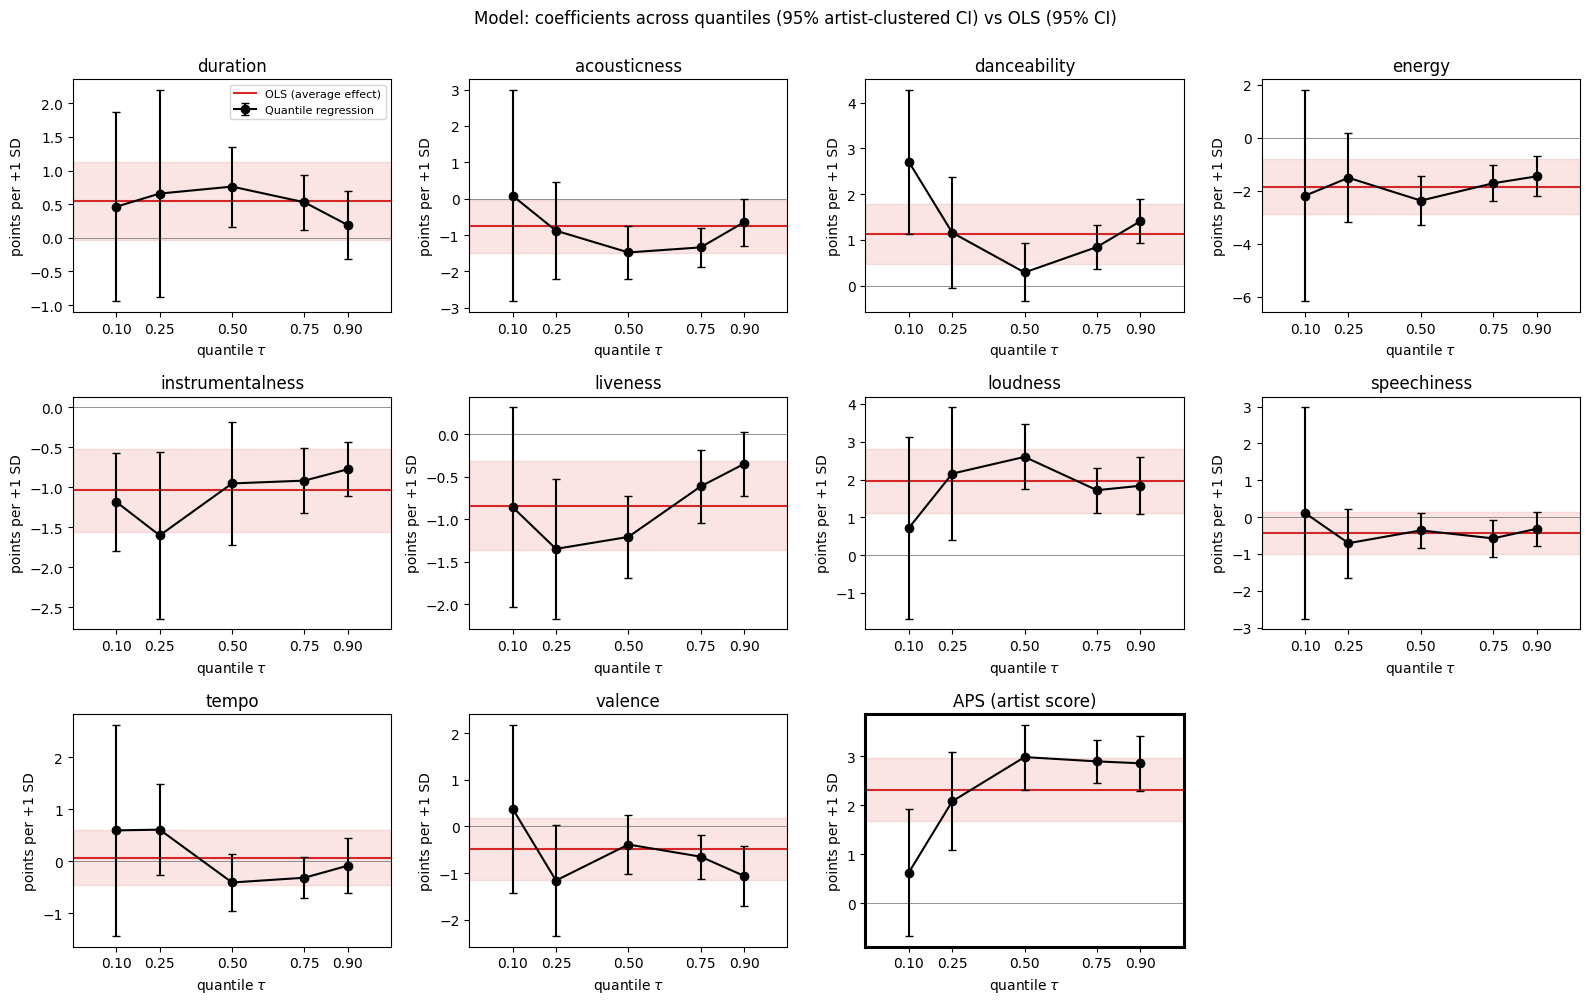

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10)); axes = axes.ravel()
for i, z in enumerate(ZVARS):
    ax = axes[i]
    est = np.array([coef[t][z] for t in TAUS]); se = np.array([cl_se[t][z] for t in TAUS])
    ci = ols.conf_int().loc[z]
    ax.axhspan(ci[0], ci[1], color="tab:red", alpha=0.12)
    ax.axhline(ols.params[z], color="tab:red", lw=1.5, label="OLS (average effect)")
    ax.axhline(0, color="grey", lw=0.6)
    ax.errorbar(TAUS, est, yerr=1.96 * se, fmt="o-", color="k", capsize=3, label="Quantile regression")
    ax.set(title=LABEL[z], xlabel=r"quantile $\tau$", ylabel="points per +1 SD"); ax.set_xticks(TAUS)
    if z == "z_APS":
        for s in ax.spines.values(): s.set_linewidth(2.2)
axes[0].legend(fontsize=8)
for ax in axes[len(ZVARS):]: ax.axis("off")
fig.suptitle("Model: coefficients across quantiles (95% artist-clustered CI) vs OLS (95% CI)", y=1.0)
plt.tight_layout(); plt.savefig(OUT_DIR / "model_coefficients_by_quantile.png", dpi=200); plt.show()

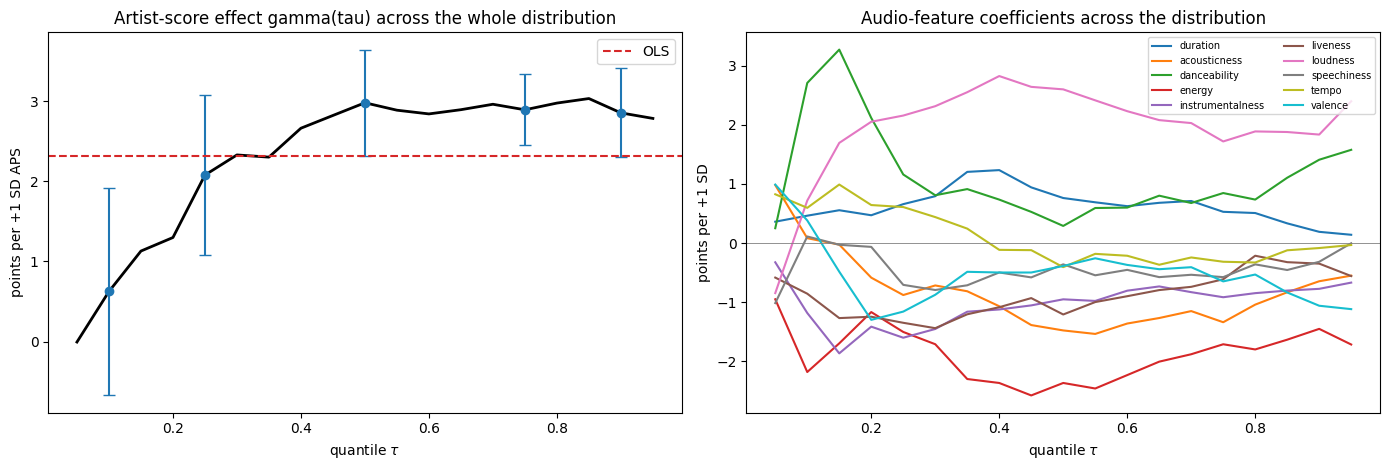

In [9]:
# Finer quantile grid (point estimates) with the five artist-clustered intervals overlaid, for the artist effect and the audio features
GRID = np.round(np.arange(0.05, 0.96, 0.05), 2)
fine = pd.DataFrame({t: sm.QuantReg(m[Y], X).fit(q=t, max_iter=5000).params for t in GRID}).T
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(GRID, fine["z_APS"], "k-", lw=2)
axes[0].errorbar(TAUS, [coef[t]["z_APS"] for t in TAUS], yerr=[1.96 * cl_se[t]["z_APS"] for t in TAUS], fmt="o", color="tab:blue", capsize=4)
axes[0].axhline(ols.params["z_APS"], color="tab:red", ls="--", label="OLS")
axes[0].set(title="Artist-score effect gamma(tau) across the whole distribution", xlabel=r"quantile $\tau$", ylabel="points per +1 SD APS"); axes[0].legend()
for z in ZVARS[:-1]:
    axes[1].plot(GRID, fine[z], label=LABEL[z], lw=1.5)
axes[1].axhline(0, color="grey", lw=0.6)
axes[1].set(title="Audio-feature coefficients across the distribution", xlabel=r"quantile $\tau$", ylabel="points per +1 SD")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(OUT_DIR / "quantile_process.png", dpi=200); plt.show()

## Do the slopes differ across quantiles?

For each coefficient we test whether the effect on high-popularity songs equals the effect on low-popularity songs:

$$H_0:\ \beta_j(0.90) = \beta_j(0.10) \qquad\text{vs}\qquad H_1:\ \beta_j(0.90) \neq \beta_j(0.10)$$

and likewise 0.75 vs 0.25, using a Wald test built from the artist-clustered covariance of the coefficient estimates (this plays the role of the paper's slope-equality test, one coefficient at a time). Holm-adjusted p-values account for testing many coefficients. A rejection means a single OLS slope would misdescribe the relationship.

In [10]:
def holm(p):
    p = np.asarray(p); mm = len(p); order = np.argsort(p)
    adj = np.minimum(np.maximum.accumulate((mm - np.arange(mm)) * p[order]), 1.0)
    out = np.empty(mm); out[order] = adj; return out

rows = []
for lo, hi in [(0.10, 0.90), (0.25, 0.75)]:
    kl, kh = TAUS.index(lo), TAUS.index(hi)
    d_obs = np.array([coef[hi][n] - coef[lo][n] for n in NAMES])
    var = np.diag(cl_cov[(hi, hi)]) + np.diag(cl_cov[(lo, lo)]) - 2 * np.diag(cl_cov[(hi, lo)])
    assert (var > 0).all(), "non-positive variance for a slope difference; the covariance estimate is unreliable"
    se = np.sqrt(var)
    p = 2 * norm.sf(np.abs(d_obs / se))
    t = pd.DataFrame({"comparison": f"tau {hi} vs {lo}", "variable": [LABEL[n] for n in NAMES],
                      "beta(hi) - beta(lo)": d_obs, "clustered SE": se, "p-value": p})
    t = t[t["variable"] != "Intercept"].copy()
    t["Holm p"] = holm(t["p-value"].to_numpy()); t["differs at 5%?"] = np.where(t["Holm p"] < 0.05, "yes", "no")
    rows.append(t)
slope_tests = pd.concat(rows, ignore_index=True)
display(slope_tests.round(4))

,comparison,variable,beta(hi) - beta(lo),clustered SE,p-value,Holm p,differs at 5%?
0,tau 0.9 vs 0.1,duration,-0.2729,0.7355,0.7106,1.0000,no
1,tau 0.9 vs 0.1,acousticness,-0.7286,1.4727,0.6208,1.0000,no
2,tau 0.9 vs 0.1,danceability,-1.2986,0.8331,0.1191,1.0000,no
3,tau 0.9 vs 0.1,energy,0.7298,2.0360,0.7200,1.0000,no
4,tau 0.9 vs 0.1,instrumentalness,0.4085,0.3585,0.2544,1.0000,no
5,tau 0.9 vs 0.1,liveness,0.5084,0.6094,0.4041,1.0000,no
6,tau 0.9 vs 0.1,loudness,1.1166,1.2488,0.3712,1.0000,no
7,tau 0.9 vs 0.1,speechiness,-0.4283,1.4825,0.7727,1.0000,no
8,tau 0.9 vs 0.1,tempo,-0.6798,1.0539,0.5189,1.0000,no
9,tau 0.9 vs 0.1,valence,-1.4425,0.9347,0.1227,1.0000,no


## What the model predicts: fitted quantiles for different artist scores

To make the model concrete, the table gives the fitted quantiles of popularity for a song with **average audio features** (all audio $\tilde{x}=0$) by an artist at different positions of the APS distribution. Predictions are clipped to the 0-100 range of the popularity index.

Predicted popularity quantiles, average audio profile:


,tau=0.1,tau=0.25,tau=0.5,tau=0.75,tau=0.9
APS = 21.0 (10th pct of artists),21.1,41.9,55.7,65.0,71.6
APS = 43.2 (25th pct of artists),21.6,43.6,58.0,67.3,73.8
APS = 73.4 (50th pct of artists),22.3,45.8,61.2,70.4,76.9
APS = 89.6 (75th pct of artists),22.6,47.0,63.0,72.0,78.6
APS = 97.3 (90th pct of artists),22.8,47.6,63.8,72.8,79.3
APS = 99.9 (99th pct of artists),22.8,47.8,64.1,73.1,79.6


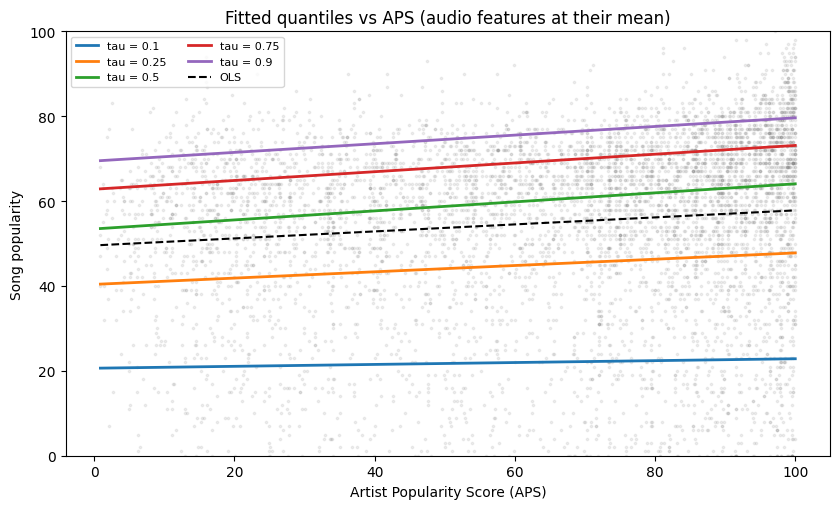

In [11]:
aps_levels = m["APS"].quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
fan = pd.DataFrame(index=[f"APS = {v:.1f}  ({int(q*100)}th pct of artists)" for q, v in aps_levels.items()],
                   columns=[f"tau={t}" for t in TAUS], dtype=float)
for (q, v), idx in zip(aps_levels.items(), fan.index):
    zv = (v - MU["APS"]) / SD["APS"]
    for t in TAUS:
        fan.loc[idx, f"tau={t}"] = np.clip(coef[t]["const"] + coef[t]["z_APS"] * zv, 0, 100)
print("Predicted popularity quantiles, average audio profile:")
display(fan.round(1))

aps_sd, aps_mean = SD["APS"], MU["APS"]
zgrid = np.linspace(m["z_APS"].min(), m["z_APS"].max(), 100)
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.scatter(m["APS"], m[Y], s=3, alpha=0.12, color="grey")
for t in TAUS:
    ax.plot(zgrid * aps_sd + aps_mean, coef[t]["const"] + coef[t]["z_APS"] * zgrid, lw=2, label=f"tau = {t}")
ax.plot(zgrid * aps_sd + aps_mean, ols.params["const"] + ols.params["z_APS"] * zgrid, "k--", lw=1.5, label="OLS")
ax.set(xlabel="Artist Popularity Score (APS)", ylabel="Song popularity", ylim=(0, 100),
       title="Fitted quantiles vs APS (audio features at their mean)")
ax.legend(ncol=2, fontsize=8); plt.tight_layout(); plt.savefig(OUT_DIR / "aps_quantile_lines.png", dpi=200); plt.show()

## Residual diagnostics

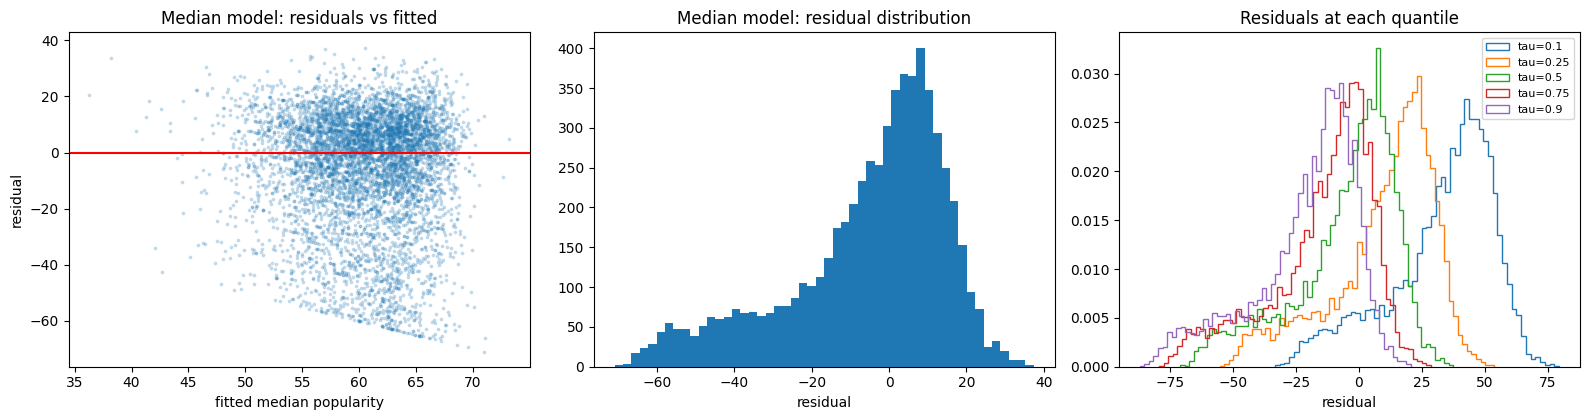

Most under-predicted songs (much more popular than the model expects):


,song_name,artist,song_popularity,fitted_median,residual,APS
3926,Eastside (with Halsey & Khalid),Gnar feat. Lil Yachty,98,60.6,37.4,91.6
64,Beautiful (feat. Camila Cabello),Carole King,94,57.0,37.0,16.0
5161,Jackie Chan,Tiësto & Dzeko feat. Preme & Post Malone,93,57.8,35.2,23.5
3952,Youngblood,3OH!3,90,55.7,34.3,18.7
10113,Nevermind,Dennis Lloyd,90,55.9,34.1,52.7
3007,Be Alright,Dean Lewis,96,62.1,33.9,84.0
3763,A Catalogue Of Afternoons,Max Richter,72,38.2,33.8,56.9
2880,Better,Khalid,95,61.4,33.6,98.1


Most over-predicted songs (much less popular than expected):


,song_name,artist,song_popularity,fitted_median,residual,APS
13879,We Outta Here! (feat. Young Nudy),Lil Yachty feat. Young Nudy,0,71.0,-71.0,91.6
8162,The Watcher 2,"Jay‐Z feat. Dr. Dre, Rakim & Truth Hurts",0,69.5,-69.5,97.3
4188,If I Can't,50 Cent,0,68.6,-68.6,96.4
7822,Jet Lag (feat. Young Scooter),Future & Juice WRLD feat. Young Scooter,0,67.2,-67.2,99.4
7668,Oxy (feat. Lil Wayne),Future feat. Lil Wayne,0,66.6,-66.6,99.4
10824,Realer N Realer,Future & Juice WRLD,0,66.3,-66.3,99.4
14167,7 Am Freestyle,Future & Juice WRLD,0,66.2,-66.2,99.4
6732,Dat Side,Cyhi the Prynce feat. Kanye West,1,67.1,-66.1,99.7


In [12]:
r50 = fits[0.50]
resid = m[Y] - r50.fittedvalues
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].scatter(r50.fittedvalues, resid, s=3, alpha=0.2); ax[0].axhline(0, color="r")
ax[0].set(title="Median model: residuals vs fitted", xlabel="fitted median popularity", ylabel="residual")
ax[1].hist(resid, bins=50); ax[1].set(title="Median model: residual distribution", xlabel="residual")
for t in TAUS:
    ax[2].hist(m[Y] - fits[t].fittedvalues, bins=60, histtype="step", label=f"tau={t}", density=True)
ax[2].set(title="Residuals at each quantile", xlabel="residual"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "residual_diagnostics.png", dpi=200); plt.show()

# Songs the median model finds most surprising (largest absolute residuals), for context
tmp = m.assign(fitted_median=r50.fittedvalues, residual=resid)
cols = ["song_name", "artist", "song_popularity", "fitted_median", "residual", "APS"]
print("Most under-predicted songs (much more popular than the model expects):"); display(tmp.nlargest(8, "residual")[cols].round(1))
print("Most over-predicted songs (much less popular than expected):"); display(tmp.nsmallest(8, "residual")[cols].round(1))

## Save results

In [13]:
tab_C.to_csv(OUT_DIR / "model_coefficients_standardised.csv")
coef_long.to_csv(OUT_DIR / "model_coefficients_long.csv", index=False)
stats.to_csv(OUT_DIR / "variable_summary_statistics.csv")
slope_tests.to_csv(OUT_DIR / "slope_equality_tests.csv", index=False)
fit_stats.to_csv(OUT_DIR / "model_fit_statistics.csv")
ols_stats.to_csv(OUT_DIR / "ols_fit_statistics.csv")
summary.to_csv(OUT_DIR / "holdout_validation.csv")
fan.to_csv(OUT_DIR / "predicted_quantiles_by_APS.csv")
print("Saved to", OUT_DIR.resolve())

Saved to C:\Users\kiwib\Desktop\Latex\Spotify Project\model_c_outputs
